# 7CS537 CW2, Notebook 04: XGBoost under time-ordered testing

**Student number:** 100810453

**Purpose:** train the supervised layer of the CW2 triage system, XGBoost, and measure how it performs when it is trained on earlier days and tested on a later day. This is the baseline the autoencoder (Notebook 05) has to improve on.

**Why this matters:** in CW1, XGBoost reached an MCC of 0.9972 on a random split. Notebook 03 showed two reasons that figure is optimistic: related flows sit on both sides of a random split (98.3% of PortScan test flows had an identical PortScan flow in training), and each attack family appears on one day only, so a real SOC model always meets new families later in time. This notebook measures what happens when that is taken into account.

**Experiments (splits built in Notebook 03):**

| Experiment | Train | Test | Question |
|---|---|---|---|
| Reference (random) | CW1 70% | CW1 15% | Does CW2 reproduce CW1's result on attack families the model has seen? |
| E1 (main) | Monday to Thursday | Friday | How well does XGBoost detect Botnet, DDoS and PortScan, which it never saw? |
| E2 Wednesday | Monday and Tuesday | Wednesday | Does knowing brute force help with DoS? |
| E2 Thursday | Monday to Wednesday | Thursday | Does knowing brute force and DoS help with web attacks and infiltration? |

**Inputs:** `data/cicids2017_clean.parquet`, `outputs/01_feature_list.txt` (CW1), `cw2/data/03_splits.parquet`, `cw2/outputs/03_run_config.json`, `cw2/outputs/03_identical_flows_breakdown.csv`.

**Outputs:** `cw2/outputs/04_*` (results tables, charts, run configuration), `cw2/models/04_xgb_*.json` (trained models), `cw2/data/04_xgb_test_scores.parquet` (scores for Notebook 06).

**How to run:** from the `cw2/` folder, after Notebook 03, run all cells from a fresh kernel. To save the outputs inside the notebook, run from the repository folder in Terminal: `jupyter nbconvert --to notebook --execute --inplace cw2/04_xgboost_chronological.ipynb`. Expected run time: several minutes (four XGBoost models).

## 1. Setup and configuration
**What:** imports, paths and settings.

**Why:** the XGBoost settings are exactly those used in CW1 (up to 1,000 trees, learning rate 0.1, depth 8, 80% row and column sampling, early stopping after 30 rounds without improvement in validation PR-AUC). Keeping them identical means any change in results comes from the testing design, not from different model settings. The alert threshold stays at 0.5, as in CW1, so results are comparable; threshold choice is examined in Notebook 06.

In [1]:
import os
import json
import time
import hashlib
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, matthews_corrcoef)

try:
    from IPython.display import display
except ImportError:
    display = print

RANDOM_STATE = 42
N_JOBS = -1
THRESHOLD = 0.5
XGB_PARAMS = dict(n_estimators=1000, learning_rate=0.1, max_depth=8, subsample=0.8, colsample_bytree=0.8,
                  tree_method="hist", eval_metric="aucpr", n_jobs=N_JOBS, random_state=RANDOM_STATE)
EARLY_STOPPING_ROUNDS = 30

ROOT = ".." if os.path.exists(os.path.join("..", "outputs", "01_feature_list.txt")) else "."
DATA_FILE = os.path.join(ROOT, "data", "cicids2017_clean.parquet")
CW1_OUT = os.path.join(ROOT, "outputs")
CW2_DIR = os.path.join(ROOT, "cw2")
OUT_DIR = os.path.join(CW2_DIR, "outputs")
MODEL_DIR = os.path.join(CW2_DIR, "models")
SPLIT_FILE = os.path.join(CW2_DIR, "data", "03_splits.parquet")
SCORE_FILE = os.path.join(CW2_DIR, "data", "04_xgb_test_scores.parquet")
os.makedirs(MODEL_DIR, exist_ok=True)

print("xgboost", xgb.__version__, "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

xgboost 3.4.1 | scikit-learn 1.9.1 | pandas 3.0.6


## 2. Load the data and the Notebook 03 splits
**What:** loads the cleaned data, the 62 features and the saved splits, then checks the data fingerprint against the one Notebook 03 recorded.

**Why:** the split file refers to flows by their position. The fingerprint check proves the data is the same file in the same row order, so "row 1,000" means the same flow in both notebooks.

In [2]:
if os.path.exists(DATA_FILE):
    df = pd.read_parquet(DATA_FILE)
else:
    df = pd.read_pickle(DATA_FILE.replace(".parquet", ".pkl"))
for col in ["Label", "attack_family", "source_file"]:
    df[col] = df[col].astype(str)
with open(os.path.join(CW1_OUT, "01_feature_list.txt")) as fh:
    feature_cols = [line.strip() for line in fh if line.strip()]
with open(os.path.join(OUT_DIR, "03_run_config.json")) as fh:
    nb03_config = json.load(fh)

h = pd.util.hash_pandas_object(df[["Label", "source_file"]], index=False).to_numpy()
fingerprint = hashlib.sha256(h.tobytes()).hexdigest()[:16]
assert fingerprint == nb03_config["data_fingerprint"], "Data differs from Notebook 03; re-run Notebook 03"

splits = pd.read_parquet(SPLIT_FILE)
assert len(splits) == len(df) and (splits["row_id"].to_numpy() == np.arange(len(df))).all()

X_all = df[feature_cols].to_numpy(dtype=np.float32)
y_all = df["is_attack"].to_numpy().astype(int)
labels = df["Label"].to_numpy()
print(f"{len(df):,} flows, {len(feature_cols)} features. Fingerprint {fingerprint} matches Notebook 03.")

2,496,544 flows, 62 features. Fingerprint cb8a0f0b8bd9cf88 matches Notebook 03.


## 3. Evaluation helpers
**What:** the same metrics as CW1, plus two additions for CW2:
- **Detection rate per label**, so a good overall figure cannot hide a family the model misses completely.
- **False alarms on the test day**, as a raw count. Each test set is one working day of capture, so this is the number of benign flows an analyst would be asked to look at that day.

**Why MCC and PR-AUC lead:** test days have very different attack shares (35.8% on Friday, 0.55% on Thursday). Accuracy rewards the majority class; MCC uses all four cells of the confusion matrix, and PR-AUC measures ranking quality without choosing a threshold.

In [3]:
def evaluate(name, y_true, score, threshold=THRESHOLD):
    y_pred = (score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    both_classes = len(np.unique(y_true)) == 2
    return {
        "experiment": name,
        "threshold": threshold,
        "test_flows": len(y_true),
        "attack_share_pct": 100 * y_true.mean(),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "detection_rate": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "fpr": fp / (fp + tn) if (fp + tn) else 0.0,
        "mcc": matthews_corrcoef(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, score) if both_classes else np.nan,
        "pr_auc": average_precision_score(y_true, score) if both_classes else np.nan,
        "TN": int(tn), "FP_false_alarms": int(fp), "FN_missed_attacks": int(fn), "TP": int(tp),
    }

def per_label(name, idx, score, threshold=THRESHOLD):
    # Share of each label flagged as an attack. For BENIGN this is the false positive rate.
    t = pd.DataFrame({"Label": labels[idx], "flagged": score >= threshold})
    out = t.groupby("Label").agg(test_flows=("flagged", "size"), flagged=("flagged", "sum"))
    out["flagged_pct"] = 100 * out["flagged"] / out["test_flows"]
    out.insert(0, "experiment", name)
    return out.reset_index()

## 4. Train and test XGBoost for each experiment
**What:** for each experiment, takes that experiment's training, validation and test flows from the split file, sets the class weight from its own training data, trains with early stopping on its own validation data, and scores the test day.

**Why the class weight is recalculated each time:** the share of attacks in training differs a lot between experiments (E2 Wednesday has only 7,777 attack flows in training). `scale_pos_weight` = benign flows / attack flows in that training set, so attacks are not ignored.

**Why validation never comes from the test day:** early stopping is a decision made with data. Making it on the test day would leak test information into the model.

In [4]:
EXPERIMENTS = ["random", "E1", "E2_Wednesday", "E2_Thursday"]
results, label_tables, models, run_info = [], [], {}, {}
scores_out = pd.DataFrame({"row_id": np.arange(len(df))})

for exp in EXPERIMENTS:
    role = splits[exp].astype(str).to_numpy()
    tr, va, te = (np.where(role == r)[0] for r in ["train", "val", "test"])
    spw = float((y_all[tr] == 0).sum() / (y_all[tr] == 1).sum())
    model = XGBClassifier(early_stopping_rounds=EARLY_STOPPING_ROUNDS, scale_pos_weight=spw, **XGB_PARAMS)
    t0 = time.time()
    model.fit(X_all[tr], y_all[tr], eval_set=[(X_all[va], y_all[va])], verbose=False)
    fit_s = time.time() - t0
    score = model.predict_proba(X_all[te])[:, 1]

    row = evaluate(exp, y_all[te], score)
    row.update({"train_flows": len(tr), "train_attack_flows": int(y_all[tr].sum()),
                "scale_pos_weight": spw, "trees": model.best_iteration + 1, "fit_time_s": fit_s})
    results.append(row)
    label_tables.append(per_label(exp, te, score))
    scores_out[exp] = np.nan
    scores_out.loc[te, exp] = score
    model.save_model(os.path.join(MODEL_DIR, f"04_xgb_{exp}.json"))
    models[exp] = model
    run_info[exp] = {"scale_pos_weight": spw, "trees": int(model.best_iteration + 1), "fit_time_s": round(fit_s, 1)}
    print(f"{exp}: trees={row['trees']}, MCC={row['mcc']:.4f}, detection={row['detection_rate']:.4f}, "
          f"false alarms={row['FP_false_alarms']:,}, missed={row['FN_missed_attacks']:,} ({fit_s:.0f} s)")

res = pd.DataFrame(results).set_index("experiment")
res.to_csv(f"{OUT_DIR}/04_xgb_results.csv")
labels_res = pd.concat(label_tables, ignore_index=True)
labels_res.to_csv(f"{OUT_DIR}/04_xgb_detection_by_label.csv", index=False)
scores_out.to_parquet(SCORE_FILE, index=False)
display(res[["test_flows", "attack_share_pct", "mcc", "detection_rate", "precision", "fpr", "pr_auc",
             "FP_false_alarms", "FN_missed_attacks", "trees"]].round(4))

random: trees=231, MCC=0.9972, detection=0.9993, false alarms=255, missed=43 (15 s)


E1: trees=219, MCC=0.0187, detection=0.0012, false alarms=92, missed=219,834 (12 s)


E2_Wednesday: trees=13, MCC=0.0135, detection=0.0005, false alarms=36, missed=193,487 (1 s)


E2_Thursday: trees=394, MCC=0.8694, detection=0.8173, false alarms=142, missed=398 (16 s)


,test_flows,attack_share_pct,mcc,detection_rate,precision,fpr,pr_auc,FP_false_alarms,FN_missed_attacks,trees
experiment,,,,,,,,,,
random,374482,17.0238,0.9972,0.9993,0.9960,0.0008,0.9999,255,43,231
E1,614833,35.7965,0.0187,0.0012,0.7349,0.0002,0.7871,92,219834,219
E2_Wednesday,586409,33.0128,0.0135,0.0005,0.7410,0.0001,0.5195,36,193487,13
E2_Thursday,396284,0.5499,0.8694,0.8173,0.9262,0.0004,0.8309,142,398,394


**What this shows** (`04_xgb_results.csv`, run of 14 Nov 2026):

| Experiment | Test attacks | Detected | Missed | False alarms | MCC | PR-AUC |
|---|---|---|---|---|---|---|
| Reference (random split) | 63,751 | 99.93% | 43 | 255 | 0.9972 | 0.9999 |
| E1, Friday (main) | 220,089 | 0.12% (255) | 219,834 | 92 | 0.019 | 0.787 |
| E2, Wednesday | 193,590 | 0.05% (103) | 193,487 | 36 | 0.013 | 0.519 |
| E2, Thursday | 2,179 | 81.7% (1,781) | 398 | 142 | 0.869 | 0.831 |

- **This is the key finding of Notebook 04.** The same model that scores an MCC of 0.9972 on a random split detects 0.12% of Friday's attacks when it has only been trained on earlier days. On Wednesday it detects 0.05%. When every attack on the test day belongs to a family it has never seen, the supervised model is almost blind.
- **It stays precise.** It raised only 92 false alarms on Friday's 394,744 benign flows (0.023%). So its alerts are trustworthy, but its silence is not evidence that the network is safe.
- **The scores still carry some signal.** Friday's PR-AUC of 0.787 is well above the 0.358 a random ranking would give (Friday is 35.8% attacks), so many attacks score higher than benign flows but stay below the 0.5 threshold. A lower threshold might catch more, but it would have to be chosen without Friday's labels; Notebook 06 examines this.
- **Thursday is the exception.** Trained on brute force and DoS, the model still flagged 81.7% of Thursday's attacks, with 142 false alarms and 92.6% precision. Section 6 shows which attacks.

## 5. Reproducibility check against CW1
**What:** compares the reference (random split) result with the XGBoost row CW1 saved in `outputs/02_model_comparison.csv`.

**Why:** same data, same split, same settings and seed should give the same model. A match shows the CW2 pipeline is consistent with the submitted CW1 work, so the differences in the time-ordered experiments come from the testing design alone. Small differences can occur if the XGBoost version or number of CPU cores differs, so the comparison is printed rather than enforced.

In [5]:
cw1 = pd.read_csv(os.path.join(CW1_OUT, "02_model_comparison.csv"), index_col="model").loc["XGBoost"]
compare = pd.DataFrame({
    "CW1 (02_model_comparison.csv)": [cw1["mcc"], cw1["recall_detection_rate"], cw1["fpr"], cw1["FP"], cw1["FN"]],
    "CW2 reference (random split)": [res.loc["random", "mcc"], res.loc["random", "detection_rate"],
                                     res.loc["random", "fpr"], res.loc["random", "FP_false_alarms"],
                                     res.loc["random", "FN_missed_attacks"]],
}, index=["MCC", "detection rate", "false positive rate", "false alarms", "missed attacks"])
compare.to_csv(f"{OUT_DIR}/04_reproducibility_vs_cw1.csv")
display(compare)

,CW1 (02_model_comparison.csv),CW2 reference (random split)
MCC,0.997207,0.997189
detection rate,0.999106,0.999326
false positive rate,0.000769,0.000821
false alarms,239.000000,255.000000
missed attacks,57.000000,43.000000


**What this shows** (`04_reproducibility_vs_cw1.csv`): the reference result is very close to CW1 but not bit-identical. MCC is 0.99719 against CW1's 0.99721, with 43 missed attacks and 255 false alarms against CW1's 57 and 239. Early stopping kept 231 trees here and 324 in CW1. The data, split, settings, seed and XGBoost version (3.4.1) are the same, so the difference most likely comes from the computing environment, for example a different NumPy build or number of CPU threads. This run recorded NumPy 2.5.3 while Notebook 03 recorded 2.5.4, which suggests the notebooks were not run in the same Python environment. The conclusion is unchanged: on a random split XGBoost performs almost perfectly, so the drop in E1 and E2 is caused by the testing design, not by a weaker pipeline.

## 6. Detection per attack type, with the flow-level ceiling
**What:** for every test set, the share of each label flagged as an attack. For E1, a ceiling column is added from Notebook 03 Section 9b: the share of each label's flows that are **not** identical to a benign training flow.

**Why the ceiling:** 37.7% of Friday's PortScan flows and 8.9% of its Bot flows have exactly the same 62 feature values as benign training traffic. A model that judges one flow at a time cannot flag those without flagging the identical benign flows too. So a PortScan detection rate should be read against a ceiling of about 62%, not 100%.

In [6]:
breakdown = pd.read_csv(os.path.join(OUT_DIR, "03_identical_flows_breakdown.csv"))
ceiling = breakdown[breakdown["split"] == "E1"].set_index("Label")
ceiling = 100 * (1 - ceiling["copy_is_benign"] / ceiling["attack_test_flows"])

table = labels_res.pivot(index="Label", columns="experiment", values="flagged_pct")[EXPERIMENTS]
counts = labels_res.pivot(index="Label", columns="experiment", values="test_flows")[EXPERIMENTS]
table.columns = [f"{c} flagged %" for c in table.columns]
counts.columns = [f"{c} test flows" for c in counts.columns]
table["E1 flow-level ceiling %"] = ceiling
summary = pd.concat([counts, table], axis=1)
summary.to_csv(f"{OUT_DIR}/04_detection_by_label_wide.csv")
display(summary.round(2))

,random test flows,E1 test flows,E2_Wednesday test flows,E2_Thursday test flows,random flagged %,E1 flagged %,E2_Wednesday flagged %,E2_Thursday flagged %,E1 flow-level ceiling %
Label,,,,,,,,,
BENIGN,310731.0,394744.0,392819.0,394105.0,0.08,0.02,0.01,0.04,NaN
Bot,292.0,1948.0,NaN,NaN,91.44,0.00,NaN,NaN,91.07
DDoS,19202.0,128011.0,NaN,NaN,99.98,0.02,NaN,NaN,100.00
DoS GoldenEye,1542.0,NaN,10282.0,NaN,100.00,NaN,0.00,NaN,NaN
DoS Hulk,25904.0,NaN,172697.0,NaN,99.98,NaN,0.00,NaN,NaN
DoS Slowhttptest,784.0,NaN,5228.0,NaN,100.00,NaN,1.97,NaN,NaN
DoS slowloris,806.0,NaN,5372.0,NaN,99.75,NaN,0.00,NaN,NaN
FTP-Patator,890.0,NaN,NaN,NaN,100.00,NaN,NaN,NaN,NaN
Heartbleed,2.0,NaN,11.0,NaN,100.00,NaN,0.00,NaN,NaN


**What this shows** (`04_detection_by_label_wide.csv`):
- **Friday (E1):** PortScan 0.25% (223 of 90,130), DDoS 0.02% (32 of 128,011), Bot 0% (0 of 1,948). These are far below the flow-level ceilings from Notebook 03 (PortScan about 62%, Bot about 91%, DDoS 100%), so the misses are not caused by identical benign flows. The model has simply never learned these patterns.
- **Wednesday (E2):** DoS Hulk, GoldenEye and slowloris 0%, Slowhttptest 1.97%, Heartbleed 0 of 11. Knowing brute force did not help with DoS.
- **Thursday (E2):** web brute force 81.8% (1,202 of 1,470), XSS 87.6% (571 of 652), SQL injection 38.1% (8 of 21), Infiltration 0 of 36. A plausible explanation is that Wednesday's DoS attacks and Thursday's web attacks are both HTTP traffic aimed at web servers, so patterns learnt from one partly carry over. This has not been tested here and should be presented as a hypothesis.
- **Comparison with CW1:** in CW1's held-out family experiment, XGBoost still detected 63.05% of DDoS. Here it detects 0.02%. One possible reason is that CW1's random split kept Friday's benign traffic and Friday's other attacks in training, so the model had seen the network conditions of that day. In E1 it has seen nothing from Friday. This is a likely explanation rather than a proven one.

## 7. Chart: seen versus new attack families
**What:** detection rate per attack label, side by side for the random split (families seen in training) and the time-ordered test that contains that label (families never seen).

**Why:** this is the central picture for the presentation's results slide. It shows how much of CW1's near-perfect score depended on having seen the attack family before.

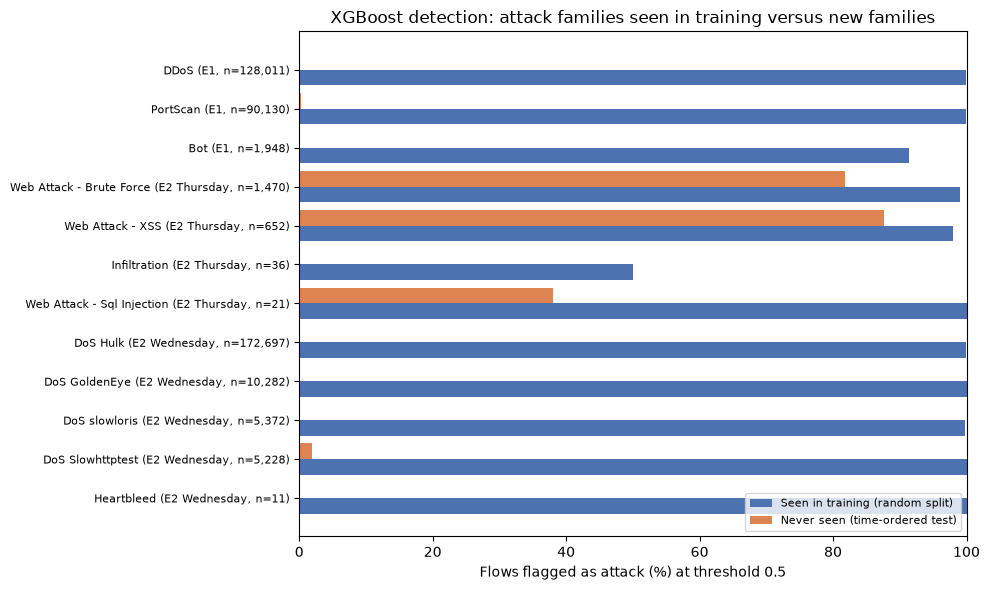

In [7]:
rows = []
for exp in ["E1", "E2_Wednesday", "E2_Thursday"]:
    t = labels_res[(labels_res["experiment"] == exp) & (labels_res["Label"] != "BENIGN")]
    for _, r in t.iterrows():
        seen = labels_res[(labels_res["experiment"] == "random") & (labels_res["Label"] == r["Label"])]
        rows.append({"Label": r["Label"], "test_day": exp, "new_family_pct": r["flagged_pct"],
                     "new_family_flows": r["test_flows"],
                     "seen_family_pct": seen["flagged_pct"].iloc[0] if len(seen) else np.nan})
chart = pd.DataFrame(rows).sort_values(["test_day", "new_family_flows"], ascending=[True, False])
chart.to_csv(f"{OUT_DIR}/04_seen_vs_new_family.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(chart))
ax.barh(y + 0.2, chart["seen_family_pct"], height=0.4, label="Seen in training (random split)", color="#4C72B0")
ax.barh(y - 0.2, chart["new_family_pct"], height=0.4, label="Never seen (time-ordered test)", color="#DD8452")
ax.set_yticks(y)
ax.set_yticklabels([f"{l} ({d.replace('_', ' ')}, n={n:,})" for l, d, n in
                    zip(chart["Label"], chart["test_day"], chart["new_family_flows"])], fontsize=8)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Flows flagged as attack (%) at threshold 0.5")
ax.set_title("XGBoost detection: attack families seen in training versus new families")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/04_seen_vs_new_family.png", dpi=200)
plt.show()

**What this shows** (`04_seen_vs_new_family.png`): every attack type is detected at close to 100% when the model has seen it (blue), and almost every one drops to near 0% when it has not (orange). The only partial exceptions are the Thursday web attacks. This chart is intended for the results slide: it shows in one picture why a supervised model alone cannot protect TeleComNet against new attack campaigns, and why CW2 adds an anomaly detector.

## 8. Save the run configuration
**What:** records settings, class weights, trees chosen by early stopping, training times and library versions.

**Why:** reproducibility evidence for the documentation, as the brief requires.

In [8]:
config = {
    "notebook": "04_xgboost_chronological",
    "data_fingerprint": fingerprint,
    "threshold": THRESHOLD,
    "xgb_params": XGB_PARAMS,
    "early_stopping_rounds": EARLY_STOPPING_ROUNDS,
    "experiments": run_info,
    "versions": {"python": platform.python_version(), "xgboost": xgb.__version__, "sklearn": sklearn.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__, "matplotlib": matplotlib.__version__},
}
with open(f"{OUT_DIR}/04_run_config.json", "w") as fh:
    json.dump(config, fh, indent=2)
print(json.dumps(run_info, indent=2))

{
  "random": {
    "scale_pos_weight": 4.874100018150894,
    "trees": 231,
    "fit_time_s": 14.5
  },
  "E1": {
    "scale_pos_weight": 8.182712236122194,
    "trees": 219,
    "fit_time_s": 11.9
  },
  "E2_Wednesday": {
    "scale_pos_weight": 97.25961167545326,
    "trees": 13,
    "fit_time_s": 1.2
  },
  "E2_Thursday": {
    "scale_pos_weight": 6.3267528970747815,
    "trees": 394,
    "fit_time_s": 15.7
  }
}


## Summary of Notebook 04

- On a random split, XGBoost reproduces the CW1 result (MCC 0.9972), confirming the pipeline.
- Trained on earlier days and tested on a later day, it detects almost none of the new attack families: 0.12% on Friday and 0.05% on Wednesday. Thursday's web attacks (81.7%) are the exception.
- It produces very few false alarms (92 on Friday), so its alerts are reliable, but it cannot be relied on to notice a new campaign.
- These results define the gap the autoencoder in Notebook 05 must address: catching new families without an unmanageable number of false alarms.

**Questions to be ready for**
- *Why keep the CW1 settings rather than tune again?* So the only thing that changes between CW1 and CW2 is the testing design. Any drop in performance is then caused by testing on new families later in time, not by different settings.
- *Why is a threshold of 0.5 used?* For comparability with CW1. Notebook 06 examines how the threshold changes alerts and missed attacks, choosing it without using the test day's labels.
- *Is XGBoost a bad model, then?* No. It is a supervised model and can only recognise patterns it was shown. On families it has seen it is almost perfect. Its weakness is structural, which is why the CW2 design pairs it with an anomaly detector.
- *Why did CW1 not show this?* CW1's random split mixed all days, so every test family had been seen in training. Notebook 03 also showed that 98.3% of PortScan test flows had an identical PortScan flow in training.